# Notebook Preprosamiento y división de datos 

## 0. Configuración de las variables

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.data import load_config, load_processed

cfg = load_config()
print("Semillas:", cfg["seeds"])
print("Split:", cfg["split"])
print("Costos:", cfg["cost"])
print("Preprocesamiento:", cfg["preprocessing"])
print("Columnas a descartar:", cfg["columns"]["drop"])

Semillas: [19, 69, 79]
Split: {'train': 0.7, 'dev': 0.15, 'test': 0.15}
Costos: {'c_FN': 10, 'c_FP': 1, 'target_precision': 0.5}
Preprocesamiento: {'add_null_indicators': True, 'clip_z': 10, 'numeric_impute': 'median', 'categorical_missing_label': 'missing', 'unknown_label': 'unknown', 'onehot_max_cardinality': 10, 'min_category_freq': 50, 'min_indicator_rows': 50, 'amt_price_point_min_freq': 100, 'skew_threshold': 2.0, 'corr_threshold': 0.95, 'corr_report_thresholds': [0.9, 0.95, 0.99], 'corr_protect': ['has_identity'], 'xgb_native_nan': False, 'no_scale': ['hour_sin', 'hour_cos']}
Columnas a descartar: ['TransactionID', 'TransactionDT']


In [2]:
# Recargar los modulos 
%load_ext autoreload
%autoreload 2

## 1.Split Temporal

### Cargar y partir

In [3]:
from src.split import temporal_split, split_summary

df = load_processed()          # ya viene ordenado por TransactionDT, float32, con has_identity
train, dev, test = temporal_split(df, cfg)

summary = split_summary(train, dev, test, cfg)
summary.round(3)

,filas,pct_filas,fraudes,tasa_fraude_%,dia_inicio,dia_fin
split,,,,,,
train,413378,70.0,14538,3.517,1.000,120.810
dev,88581,15.0,3042,3.434,120.810,152.220
test,88581,15.0,3083,3.480,152.221,182.999


### Reporte de tamaño y tasa de fraude

In [4]:
print(f"Total: {len(df):,} filas")
print(f"Fraude global: {100 * df[cfg['columns']['target']].mean():.3f}%")
display(summary.round(3))

Total: 590,540 filas
Fraude global: 3.499%


,filas,pct_filas,fraudes,tasa_fraude_%,dia_inicio,dia_fin
split,,,,,,
train,413378,70.0,14538,3.517,1.000,120.810
dev,88581,15.0,3042,3.434,120.810,152.220
test,88581,15.0,3083,3.480,152.221,182.999


### Tasa de fraude diaria coloreada por split y 

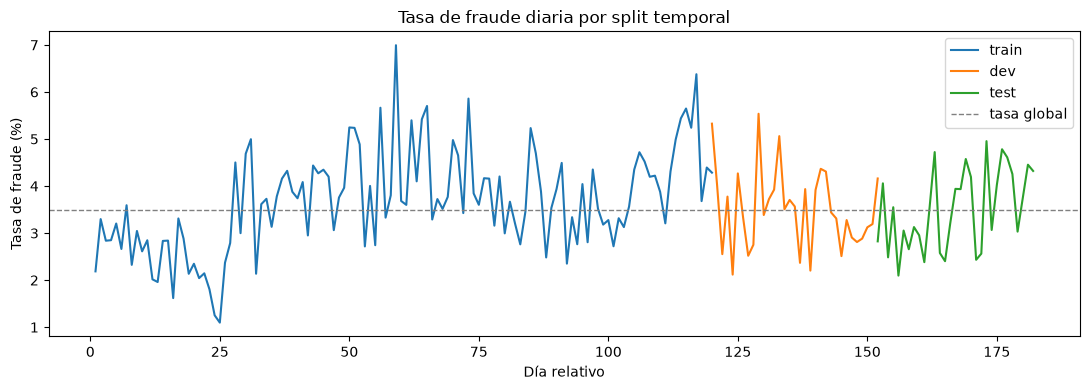

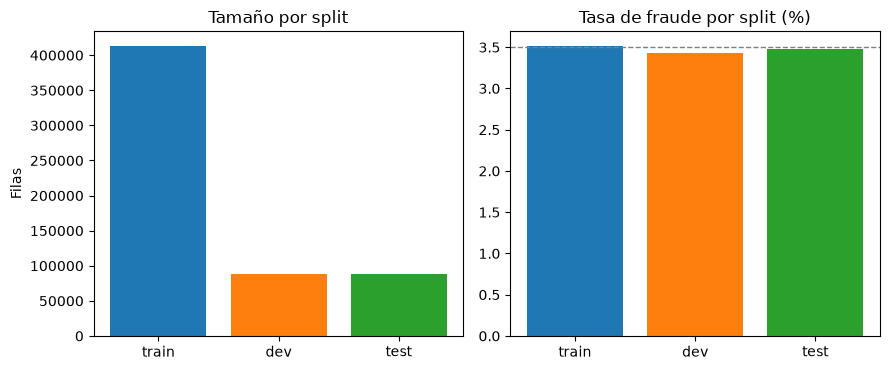

In [5]:
import matplotlib.pyplot as plt

tc, yc = cfg["columns"]["time"], cfg["columns"]["target"]
fig_dir = ROOT / cfg["paths"]["figures_dir"]
colors = {"train": "#1f77b4", "dev": "#ff7f0e", "test": "#2ca02c"}

# --- Figura 17: tasa de fraude diaria coloreada por split ---
fig, ax = plt.subplots(figsize=(11, 4))
for name, part in (("train", train), ("dev", dev), ("test", test)):
    daily = part.groupby((part[tc] // 86400).astype(int))[yc].mean() * 100
    ax.plot(daily.index, daily.values, color=colors[name], label=name, lw=1.5)
ax.axhline(100 * df[yc].mean(), color="gray", ls="--", lw=1, label="tasa global")
ax.set_xlabel("Día relativo")
ax.set_ylabel("Tasa de fraude (%)")
ax.set_title("Tasa de fraude diaria por split temporal")
ax.legend()
fig.tight_layout()
fig.savefig(fig_dir / "17_split_timeline.png", dpi=150)
plt.show()

# --- Figura 18: tamaño y tasa de fraude por split ---
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
axes[0].bar(summary.index, summary["filas"], color=[colors[s] for s in summary.index])
axes[0].set_title("Tamaño por split")
axes[0].set_ylabel("Filas")
axes[1].bar(summary.index, summary["tasa_fraude_%"], color=[colors[s] for s in summary.index])
axes[1].axhline(100 * df[yc].mean(), color="gray", ls="--", lw=1)
axes[1].set_title("Tasa de fraude por split (%)")
fig.tight_layout()
fig.savefig(fig_dir / "18_fraud_rate_by_split.png", dpi=150)
plt.show()

## 2-3. Limpieza y variables derivadas

### Aplicar a los tres splits

In [6]:
from src.preprocessing import prepare_frame, DERIVED_COLS
import pandas as pd

X_train, y_train, meta_train = prepare_frame(train, cfg)
X_dev,   y_dev,   meta_dev   = prepare_frame(dev, cfg)
X_test,  y_test,  meta_test  = prepare_frame(test, cfg)

# Mismas columnas y en el mismo orden en los tres splits
assert list(X_train.columns) == list(X_dev.columns) == list(X_test.columns)

c = cfg["columns"]
n_quitadas = len(set(c["drop"]) | {c["target"], c["amount"]})
pasos = pd.DataFrame([
    {"paso": "Datos originales", "n_columnas": train.shape[1]},
    {"paso": f"Acción 2: se quitan {n_quitadas} columnas (objetivo, id, tiempo, importe crudo)",
     "n_columnas": train.shape[1] - n_quitadas},
    {"paso": f"Acción 3: + {len(DERIVED_COLS)} derivadas", "n_columnas": X_train.shape[1]},
])
display(pasos)
print("X:", X_train.shape, X_dev.shape, X_test.shape)
print("meta:", list(meta_train.columns))

c:\Users\kevin\fintech-fraud-detection-dl\src\preprocessing.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[col] = derived[col].to_numpy()
c:\Users\kevin\fintech-fraud-detection-dl\src\preprocessing.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[col] = derived[col].to_numpy()
c:\Users\kevin\fintech-fraud-detection-dl\src\preprocessing.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns

,paso,n_columnas
0,Datos originales,435
1,"Acción 2: se quitan 4 columnas (objetivo, id, ...",431
2,Acción 3: + 4 derivadas,435


X: (413378, 435) (88581, 435) (88581, 435)
meta: ['TransactionID', 'TransactionDT', 'TransactionAmt']


### Comprobaciones

In [7]:
display(X_train[DERIVED_COLS].describe().round(3))
print("NaN en derivadas:", int(X_train[DERIVED_COLS].isna().sum().sum()))

# D2: la tasa de fraude por hora relativa debe reproducir el patrón del EDA (solo con train)
hour = ((meta_train[c["time"]] // cfg["derived"]["seconds_per_hour"]) % cfg["derived"]["hour_period"]).astype(int)
rate_hour = (y_train.groupby(hour).mean() * 100).round(2)
print("\nHoras con más fraude:\n", rate_hour.sort_values(ascending=False).head(3))
print("Horas con menos fraude:\n", rate_hour.sort_values().head(3))

# C3: los centavos más frecuentes y su tasa de fraude
cents = X_train["amt_cents"].astype(int)
tab = pd.DataFrame({"filas": cents.value_counts().head(8)})
tab["tasa_fraude_%"] = (y_train.groupby(cents).mean().reindex(tab.index) * 100).round(2)
display(tab)

,hour_sin,hour_cos,amt_log,amt_cents
count,413378.000,413378.000,413378.000,413378.000
mean,-0.366,0.241,4.384,36.753
std,0.608,0.662,0.935,42.986
min,-1.000,-1.000,0.224,0.000
25%,-0.866,-0.259,3.783,0.000
50%,-0.500,0.500,4.248,0.000
75%,0.000,0.866,4.836,95.000
max,1.000,1.000,10.372,99.000


NaN en derivadas: 0

Horas con más fraude:
 TransactionDT
8    10.01
7     9.71
9     9.56
Name: isFraud, dtype: float64
Horas con menos fraude:
 TransactionDT
13    2.17
14    2.42
15    2.47
Name: isFraud, dtype: float64


,filas,tasa_fraude_%
amt_cents,,
0,217236,3.63
95,112099,0.67
50,15830,1.93
97,5577,1.47
99,4228,2.25
47,1594,2.70
36,1094,9.51
71,940,12.98


## 4.Indicadores de nulo por patrón
Primera acción que se ajusta con train.


### Ajustar con train 

In [8]:
from src.preprocessing import NullPatternIndicators

nulls = NullPatternIndicators(min_rows=cfg["preprocessing"]["min_indicator_rows"]).fit(X_train)

n_cols_con_nulos = sum(len(v) for v in nulls.groups_.values())
print(f"Columnas con nulos agrupadas: {n_cols_con_nulos}  ->  indicadores (patrones): {len(nulls.groups_)}")

summ = nulls.summary(X_train, y_train)
print("\nGrupos con más columnas:")
display(summ.sort_values("n_cols", ascending=False).head(10).round(2))

print("\nGrupos con mayor diferencia de fraude (nulo vs presente):")
display(summ.reindex(summ["dif_pp"].abs().sort_values(ascending=False).index).head(10).round(2))

Columnas con nulos agrupadas: 339  ->  indicadores (patrones): 65

Grupos con más columnas:


,n_cols,ejemplo,nulo_%,fraude_si_nulo_%,fraude_si_presente_%,dif_pp
grupo,,,,,,
null_pat_37,46,"V217, V218, V219",75.60,2.33,7.20,-4.87
null_pat_35,31,"V167, V168, V172",74.22,2.17,7.39,-5.22
null_pat_34,29,"V138, V139, V140",84.23,3.39,4.19,-0.80
null_pat_30,23,"V12, V13, V14",14.81,4.67,3.32,1.36
null_pat_32,22,"V53, V54, V55",15.13,5.36,3.19,2.17
null_pat_33,20,"V75, V76, V77",16.54,4.54,3.32,1.22
null_pat_36,19,"V169, V170, V171",74.22,2.17,7.39,-5.22
null_pat_39,18,"V322, V323, V324",84.16,3.39,4.21,-0.83
null_pat_31,18,"V35, V36, V37",29.57,3.55,3.50,0.05



Grupos con mayor diferencia de fraude (nulo vs presente):


,n_cols,ejemplo,nulo_%,fraude_si_nulo_%,fraude_si_presente_%,dif_pp
grupo,,,,,,
null_pat_16,1,D7,93.53,2.74,14.78,-12.04
null_pat_22,1,D14,89.12,2.57,11.31,-8.74
null_pat_5,2,"addr1, addr2",11.50,11.25,2.51,8.73
null_pat_20,1,D12,88.56,2.52,11.22,-8.70
null_pat_21,1,D13,89.34,2.64,10.86,-8.22
null_pat_15,1,D6,87.28,2.55,10.15,-7.60
null_pat_42,2,"id_03, id_04",88.11,2.64,10.01,-7.37
null_pat_17,4,"D8, D9, id_09",86.41,2.54,9.75,-7.22
null_pat_7,1,dist2,92.95,3.08,9.28,-6.20


### Coherencia en dev y test, y columnas sin cobertura

In [9]:
for name, Xs in (("dev", X_dev), ("test", X_test)):
    coh = nulls.coherence(Xs)
    unc = nulls.uncovered_null_columns(Xs)
    print(f"[{name}] coherencia mínima: {coh.min():.3f} | grupos con coherencia < 1: {(coh < 1).sum()}"
          f" | columnas con nulos sin indicador: {len(unc)}")
    if unc:
        print("   ejemplos:", unc[:8])

# Indicadores listos para dev y test: mismas columnas y mismo orden que train
I_train, I_dev, I_test = (nulls.transform(X) for X in (X_train, X_dev, X_test))
assert list(I_train.columns) == list(I_dev.columns) == list(I_test.columns)
print("\nIndicadores:", I_train.shape, I_dev.shape, I_test.shape)

[dev] coherencia mínima: 1.000 | grupos con coherencia < 1: 0 | columnas con nulos sin indicador: 43
   ejemplos: ['V95', 'V96', 'V97', 'V98', 'V99', 'V100', 'V101', 'V102']
[test] coherencia mínima: 0.375 | grupos con coherencia < 1: 2 | columnas con nulos sin indicador: 43
   ejemplos: ['V95', 'V96', 'V97', 'V98', 'V99', 'V100', 'V101', 'V102']

Indicadores: (413378, 65) (88581, 65) (88581, 65)


In [10]:
# 1) Grupos cuya coherencia cae en test
coh_test = nulls.coherence(X_test)
for g, v in coh_test[coh_test < 1].items():
    cols, rep = nulls.groups_[g], nulls.rep_[g]
    rep_null = X_test[rep].isna()
    divergen = [c for c in cols if not (X_test[c].isna() == rep_null).all()]
    print(f"{g}: n_cols={len(cols)} | coherencia={v:.3f} | ejemplo={cols[:3]} | "
          f"filas nulas (rep.) en test={int(rep_null.sum())} | columnas que divergen={len(divergen)}")

# 2) ¿Cuántas filas respaldan la señal de null_pat_39 en train?
m39 = I_train["null_pat_39"] == 1
print(f"\nnull_pat_39 en train: {int(m39.sum())} filas nulas, {int(y_train[m39].sum())} fraudes")

# 3) Columnas con nulos sin indicador: ¿qué bloque son y a cuántas filas afectan?
for name, Xs in (("dev", X_dev), ("test", X_test)):
    unc = nulls.uncovered_null_columns(Xs)
    filas = Xs[unc].isna().any(axis=1)
    print(f"\n[{name}] {len(unc)} columnas ({unc[0]} … {unc[-1]}) | "
          f"filas con algún nulo ahí: {int(filas.sum())} ({100 * filas.mean():.2f}%) | "
          f"nulos de esas columnas en train: {int(X_train[unc].isna().sum().sum())}")

null_pat_34: n_cols=29 | coherencia=0.621 | ejemplo=['V138', 'V139', 'V140'] | filas nulas (rep.) en test=78929 | columnas que divergen=11
null_pat_45: n_cols=8 | coherencia=0.375 | ejemplo=['id_11', 'id_15', 'id_28'] | filas nulas (rep.) en test=70390 | columnas que divergen=5

null_pat_39 en train: 347917 filas nulas, 11779 fraudes

[dev] 43 columnas (V95 … V137) | filas con algún nulo ahí: 239 (0.27%) | nulos de esas columnas en train: 0

[test] 43 columnas (V95 … V137) | filas con algún nulo ahí: 75 (0.08%) | nulos de esas columnas en train: 0


## 5. Imputación

In [11]:
from src.preprocessing import Imputer

# Los indicadores se calculan sobre los datos CON nulos (celda 8: I_train, I_dev, I_test); ahora se imputa
imputer = Imputer(cfg).fit(X_train)
Xi_train, Xi_dev, Xi_test = (imputer.transform(X) for X in (X_train, X_dev, X_test))

print(f"Numéricas: {len(imputer.num_cols_)} | categóricas (texto + códigos): {len(imputer.cat_cols_)}")
print("Numéricas con mediana 0:", sum(v == 0 for v in imputer.fill_.values()))
for name, Xi in (("train", Xi_train), ("dev", Xi_dev), ("test", Xi_test)):
    print(f"[{name}] NaN tras imputar: {int(Xi.isna().sum().sum())} | forma: {Xi.shape}")
assert list(Xi_train.columns) == list(Xi_dev.columns) == list(Xi_test.columns)

# --- A10 en acción: D7 falta vs D7 vale 0 ---
g_d7 = next(g for g, cols in nulls.groups_.items() if "D7" in cols)
m_null = I_train[g_d7] == 1
m_zero = X_train["D7"] == 0
tabla = pd.DataFrame(
    {"filas": [int(m_null.sum()), int(m_zero.sum())],
     "fraude_%": [100 * y_train[m_null].mean(), 100 * y_train[m_zero].mean()]},
    index=["D7 falta (se imputa)", "D7 vale 0 (valor real)"])
print(f"\nMediana de D7 usada para imputar: {imputer.fill_['D7']}")
display(tabla.round(2))

# --- Categóricas: cuántos 'missing' y qué valores dominan ---
for c in ["DeviceType", "id_31", "card2", "addr1"]:
    n_miss = int((Xi_train[c] == cfg["preprocessing"]["categorical_missing_label"]).sum())
    print(f"{c}: {n_miss} 'missing' en train | top: {Xi_train[c].value_counts().head(3).to_dict()}")

Numéricas: 398 | categóricas (texto + códigos): 37
Numéricas con mediana 0: 230
[train] NaN tras imputar: 0 | forma: (413378, 435)
[dev] NaN tras imputar: 0 | forma: (88581, 435)
[test] NaN tras imputar: 0 | forma: (88581, 435)

Mediana de D7 usada para imputar: 0.0


,filas,fraude_%
D7 falta (se imputa),386632,2.74
D7 vale 0 (valor real),14509,21.20


DeviceType: 305981 'missing' en train | top: {'missing': 305981, 'desktop': 65963, 'mobile': 41434}
id_31: 306142 'missing' en train | top: {'missing': 306142, 'chrome 63.0': 21816, 'mobile safari 11.0': 11029}
card2: 6520 'missing' en train | top: {'321': 33645, '111': 31429, '555': 29649}
addr1: 47518 'missing' en train | top: {'missing': 47518, '299': 32938, '325': 29730}


## 6. Codificación de categóricas

### Exploración para fijar los umbrales

In [12]:
import numpy as np

cat_cols = imputer.cat_cols_
n_uniq = Xi_train[cat_cols].nunique().sort_values()
print("Cardinalidad en train (incluye 'missing'):")
display(n_uniq.to_frame("nunique").T)

# onehot_max_cardinality: ¿qué columnas entrarían en one-hot con cada corte?
for k in (5, 10, 15, 20):
    print(f"onehot_max={k:>2}: {int((n_uniq <= k).sum())} columnas en one-hot, "
          f"{int(n_uniq[n_uniq <= k].sum())} dummies como máximo")

# min_category_freq: categorías conservadas y % de filas que irían a 'desconocido' (en train y en dev)
high = [c for c in cat_cols if n_uniq[c] > cfg["preprocessing"]["onehot_max_cardinality"]]
rows = []
for thr in (20, 50, 100, 200):
    kept = unk_tr = unk_dev = 0
    for c in high:
        vc = Xi_train[c].value_counts()
        voc = set(vc[vc >= thr].index)
        kept += len(voc)
        unk_tr += (~Xi_train[c].isin(voc)).mean()
        unk_dev += (~Xi_dev[c].isin(voc)).mean()
    rows.append({"min_freq": thr, "categorias_totales": kept,
                 "%unk_train(prom.)": 100 * unk_tr / len(high), "%unk_dev(prom.)": 100 * unk_dev / len(high)})
display(pd.DataFrame(rows).round(2))

# amt_price_point_min_freq: cuántos importes exactos tienen índice propio y qué cobertura de filas dan
cents_tr = pd.Series(np.round(meta_train["TransactionAmt"].to_numpy(dtype="float64") * 100).astype("int64"))
vc = cents_tr.value_counts()
rows = [{"min_freq": t, "precios_con_indice": int((vc >= t).sum()),
         "%filas_cubiertas": 100 * vc[vc >= t].sum() / len(cents_tr)} for t in (20, 50, 100, 200, 500)]
print("\nImportes exactos distintos en train:", len(vc))
display(pd.DataFrame(rows).round(2))

# ¿Hay un '<NaN>' escrito literalmente o variantes de nulo además de 'missing'?
bad = {"nan", "<nan>", "none", "", "null"}
lit = {c: int(Xi_train[c].str.lower().isin(bad).sum()) for c in cat_cols}
print("Categorías literales tipo nulo:", {c: v for c, v in lit.items() if v})

Cardinalidad en train (incluye 'missing'):


,M2,M3,M5,M1,M9,M8,id_35,id_29,id_27,id_28,...,addr2,id_30,card3,id_31,card5,id_33,addr1,card2,DeviceInfo,card1
nunique,3,3,3,3,3,3,3,3,3,3,...,68,72,106,109,111,184,319,501,1547,12242


onehot_max= 5: 25 columnas en one-hot, 86 dummies como máximo
onehot_max=10: 25 columnas en one-hot, 86 dummies como máximo
onehot_max=15: 25 columnas en one-hot, 86 dummies como máximo
onehot_max=20: 25 columnas en one-hot, 86 dummies como máximo


,min_freq,categorias_totales,%unk_train(prom.),%unk_dev(prom.)
0,20,3281,1.08,1.21
1,50,1891,1.95,2.06
2,100,1191,2.93,3.03
3,200,755,4.19,4.26



Importes exactos distintos en train: 14862


,min_freq,precios_con_indice,%filas_cubiertas
0,20,1316,91.07
1,50,602,85.84
2,100,294,80.73
3,200,188,77.27
4,500,93,70.67


Categorías literales tipo nulo: {}


### Ajustar con train y verificar

In [13]:
from src.preprocessing import CategoricalEncoder

enc = CategoricalEncoder(cfg).fit(Xi_train, meta_train["TransactionAmt"], imputer.cat_cols_)
E_train, Idx_train = enc.transform(Xi_train, meta_train["TransactionAmt"])
E_dev,   Idx_dev   = enc.transform(Xi_dev,   meta_dev["TransactionAmt"])
E_test,  Idx_test  = enc.transform(Xi_test,  meta_test["TransactionAmt"])

assert list(E_train.columns) == list(E_dev.columns) == list(E_test.columns)
assert list(Idx_train.columns) == list(Idx_dev.columns) == list(Idx_test.columns)
for nm, E, I in (("train", E_train, Idx_train), ("dev", E_dev, Idx_dev), ("test", E_test, Idx_test)):
    assert not E.isna().any().any() and not I.isna().any().any()
    print(f"[{nm}] X_enc: {E.shape} | idx: {I.shape}")

print(f"\nBaja cardinalidad (one-hot): {len(enc.low_)} columnas -> "
      f"{sum(c.split('__')[0] in enc.low_ for c in E_train.columns)} dummies")
print(f"Alta cardinalidad (freq + idx): {len(enc.high_)} columnas")
sizes = pd.Series(enc.vocab_sizes()).sort_values(ascending=False)
print("\nMayores vocabularios (para Embedding):")
display(sizes.head(10).to_frame("vocab").T)

unk = pd.DataFrame({"train": enc.unknown_rate(Xi_train), "dev": enc.unknown_rate(Xi_dev),
                    "test": enc.unknown_rate(Xi_test)}) * 100
print("\n% de filas en 'desconocido' (las 8 columnas con más en dev):")
display(unk.sort_values("dev", ascending=False).head(8).round(2))

# C3: los precios recurrentes de ejemplo y la tasa de fraude de 'otros'
amt_cents = np.round(meta_train["TransactionAmt"].to_numpy(dtype="float64") * 100).astype("int64")
ej = pd.DataFrame({"importe": [57.95, 47.95, 35.95, 150.00]})
ej["filas"] = [int((amt_cents == round(v * 100)).sum()) for v in ej["importe"]]
ej["fraude_%"] = [100 * y_train[amt_cents == round(v * 100)].mean() for v in ej["importe"]]
ej["indice"] = [enc.price_vocab_.index(round(v * 100)) + 1 if round(v * 100) in enc.price_vocab_ else 0
                for v in ej["importe"]]
display(ej.round(2))
otros = Idx_train["amt_price_point_idx"] == 0
print(f"'otros': {100 * otros.mean():.1f}% de las filas, fraude {100 * y_train[otros].mean():.2f}%")

[train] X_enc: (413378, 98) | idx: (413378, 13)
[dev] X_enc: (88581, 98) | idx: (88581, 13)
[test] X_enc: (88581, 98) | idx: (88581, 13)

Baja cardinalidad (one-hot): 25 columnas -> 85 dummies
Alta cardinalidad (freq + idx): 12 columnas

Mayores vocabularios (para Embedding):


,card1_idx,card2_idx,amt_price_point_idx,DeviceInfo_idx,addr1_idx,id_31_idx,id_30_idx,P_emaildomain_idx,card5_idx,id_33_idx
vocab,946,445,295,102,72,65,58,54,45,45



% de filas en 'desconocido' (las 8 columnas con más en dev):


,train,dev,test
card1,19.02,18.99,18.78
DeviceInfo,2.44,2.48,2.85
id_30,0.11,1.04,2.32
card2,0.51,0.79,0.86
id_33,0.19,0.47,0.82
id_31,0.19,0.25,9.33
R_emaildomain,0.19,0.16,0.15
card3,0.20,0.14,0.29


,importe,filas,fraude_%,indice
0,57.95,15426,0.36,5
1,47.95,6392,0.30,12
2,35.95,5828,0.31,14
3,150.00,6673,7.04,11


'otros': 19.3% de las filas, fraude 6.96%


## 7.Transformación de colas y escalado

In [14]:
from src.preprocessing import NumericTransformer

freq_cols = [c for c in E_train.columns if c.endswith("_freq")]
def num_block(Xi, E):
    return pd.concat([Xi[imputer.num_cols_], E[freq_cols]], axis=1)

N_train, N_dev, N_test = (num_block(a, b) for a, b in ((Xi_train, E_train), (Xi_dev, E_dev), (Xi_test, E_test)))
numtf = NumericTransformer(cfg).fit(N_train)
Z_train, Z_dev, Z_test = (numtf.transform(N) for N in (N_train, N_dev, N_test))

print(f"Columnas numéricas: {N_train.shape[1]} | sin tocar (binarias o no_scale): {len(numtf.passthrough_cols_)} "
      f"| con log1p: {len(numtf.log_cols_)} | estandarizadas: {len(numtf.scale_cols_)}")
assert list(Z_train.columns) == list(Z_dev.columns) == list(Z_test.columns)

# decisión abierta 3: sensibilidad de skew_threshold
mins = N_train[numtf.scale_cols_].min()
for thr in (1, 2, 3, 5, 10):
    n = int(((numtf.skew_ > thr) & (mins >= 0)).sum())
    print(f"skew_threshold={thr:>2}: {n} columnas con log1p")

# ¿qué familias reciben log1p?
fam = pd.Series(numtf.log_cols_).str.extract(r"^([A-Za-z]+)")[0].value_counts()
print("\nColumnas con log1p por familia:", fam.to_dict())

# comprobación en train y deriva en dev (en unidades de desviación de train)
sc = numtf.scale_cols_
print(f"\nTrain: |media| máx = {Z_train[sc].mean().abs().max():.4f} | "
      f"std entre {Z_train[sc].std().min():.3f} y {Z_train[sc].std().max():.3f}")
print("Dev: columnas con mayor desplazamiento de media (z):")
display(Z_dev[sc].mean().abs().sort_values(ascending=False).head(8).round(3).to_frame("|media_dev|"))
print("Dev: mayores valores absolutos (colas):")
display(Z_dev[sc].abs().max().sort_values(ascending=False).head(8).round(1).to_frame("max|z|"))

Columnas numéricas: 411 | sin tocar (binarias o no_scale): 11 | con log1p: 326 | estandarizadas: 400
skew_threshold= 1: 342 columnas con log1p
skew_threshold= 2: 326 columnas con log1p
skew_threshold= 3: 303 columnas con log1p
skew_threshold= 5: 281 columnas con log1p
skew_threshold=10: 240 columnas con log1p

Columnas con log1p por familia: {'V': 297, 'C': 14, 'id': 8, 'D': 5, 'dist': 2}

Train: |media| máx = 0.0240 | std entre 0.076 y 1.000
Dev: columnas con mayor desplazamiento de media (z):


,|media_dev|
D11,0.383
id_13,0.368
V10,0.307
V11,0.306
V66,0.238
id_30_freq,0.205
V302,0.204
V304,0.198


Dev: mayores valores absolutos (colas):


,max|z|
id_26,10.0
id_25,10.0
id_24,10.0
id_22,10.0
id_21,10.0
id_18,10.0
id_14,10.0
id_11,10.0


In [15]:
clip = cfg["preprocessing"]["clip_z"]
numtf = NumericTransformer(cfg).fit(N_train)
Z_train, Z_dev, Z_test = (numtf.transform(N) for N in (N_train, N_dev, N_test))
for nm, Z in (("train", Z_train), ("dev", Z_dev), ("test", Z_test)):
    A = Z[numtf.scale_cols_].abs().to_numpy()
    print(f"[{nm}] valores recortados: {100 * (A >= clip).mean():.4f}% | max|z| = {A.max():.1f}")

[train] valores recortados: 0.0903% | max|z| = 10.0
[dev] valores recortados: 0.0749% | max|z| = 10.0
[test] valores recortados: 0.2960% | max|z| = 10.0


## 8. Filtro de redundancia

### Matriz tabular, ajuste y reporte

In [16]:
from src.preprocessing import RedundancyFilter

dummy_cols = [c for c in E_train.columns if c not in freq_cols]
def tab(Z, I, E):
    return pd.concat([Z, I, E[dummy_cols]], axis=1)

T_train, T_dev, T_test = tab(Z_train, I_train, E_train), tab(Z_dev, I_dev, E_dev), tab(Z_test, I_test, E_test)
print("Matriz tabular (train):", T_train.shape)

rf = RedundancyFilter(cfg).fit(T_train, y_train)
display(rf.report(cfg["preprocessing"]["corr_report_thresholds"]))
print(f"corr_threshold={cfg['preprocessing']['corr_threshold']}: "
      f"se eliminan {len(rf.drop_cols_)} y se quedan {len(rf.keep_cols_)}")
assert "has_identity" in rf.keep_cols_

fam = pd.Series(list(rf.drop_cols_)).str.extract(r"^([A-Za-z]+)")[0].value_counts()
print("\nEliminadas por familia:", fam.to_dict())

pares = pd.DataFrame([(c, r_col, r) for c, (r_col, r) in rf.drop_cols_.items()],
                     columns=["eliminada", "reemplazada_por", "|r|"]).sort_values("|r|", ascending=False)
display(pares.head(10).round(3))

Matriz tabular (train): (413378, 561)


,eliminadas,se_quedan
umbral,,
0.90,258,303
0.95,178,383
0.99,77,484


corr_threshold=0.95: se eliminan 178 y se quedan 383

Eliminadas por familia: {'V': 104, 'null': 32, 'id': 22, 'M': 10, 'C': 3, 'card': 3, 'ProductCD': 2, 'DeviceType': 1, 'R': 1}


,eliminada,reemplazada_por,|r|
39,id_16__Found,null_pat_42,1.0
33,id_29__Found,null_pat_17,1.0
86,M4__missing,null_pat_25,1.0
92,M3__missing,null_pat_24,1.0
91,M2__missing,null_pat_24,1.0
90,M1__missing,null_pat_24,1.0
78,M6__missing,null_pat_27,1.0
75,id_16__missing,null_pat_48,1.0
0,V107,constante,1.0
169,M5__missing,null_pat_26,1.0


### Comprobación en dev y test

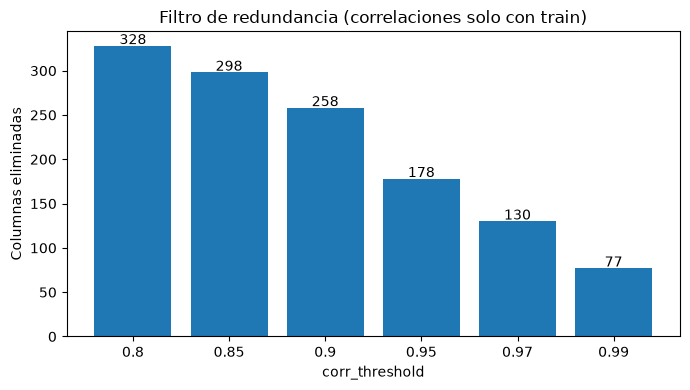

Tras el filtro: (413378, 383) (88581, 383) (88581, 383)


In [17]:
grid = [0.80, 0.85, 0.90, 0.95, 0.97, 0.99]
rep = rf.report(grid)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([str(t) for t in rep.index], rep["eliminadas"], color="#1f77b4")
for i, v in enumerate(rep["eliminadas"]):
    ax.text(i, v + 2, str(v), ha="center")
ax.set_xlabel("corr_threshold")
ax.set_ylabel("Columnas eliminadas")
ax.set_title("Filtro de redundancia (correlaciones solo con train)")
fig.tight_layout()
fig.savefig(fig_dir / "19_corr_filter_threshold.png", dpi=150)
plt.show()

F_train, F_dev, F_test = (rf.transform(T) for T in (T_train, T_dev, T_test))
assert list(F_train.columns) == list(F_dev.columns) == list(F_test.columns)
print("Tras el filtro:", F_train.shape, F_dev.shape, F_test.shape)

## 9. Desbalance de clases (decisión de diseño)

In [18]:
from src.train import compute_class_weights

cw = compute_class_weights(y_train, cfg["imbalance"]["class_weight_mode"])
print(f"Train: {cw['n0']:,} legítimas / {cw['n1']:,} fraudes -> ratio {cw['scale_pos_weight']:.1f} : 1")
print(f"class_weight = {{0: {cw['class_weight'][0]:.3f}, 1: {cw['class_weight'][1]:.3f}}} "
      f"| scale_pos_weight = {cw['scale_pos_weight']:.2f}")

tabla = pd.DataFrame(
    {"filas": [len(y_train), len(y_dev), len(y_test)],
     "fraudes": [int(y_train.sum()), int(y_dev.sum()), int(y_test.sum())]},
    index=["train", "dev", "test"])
tabla["tasa_%"] = 100 * tabla["fraudes"] / tabla["filas"]
tabla["piso_PR-AUC"] = tabla["tasa_%"] / 100
display(tabla.round(4))

# El preprocesamiento no remuestreó nada: mismas filas que el split original
assert cfg["imbalance"]["resample"] is False
assert (len(F_train), len(F_dev), len(F_test)) == (len(train), len(dev), len(test))

Train: 398,840 legítimas / 14,538 fraudes -> ratio 27.4 : 1
class_weight = {0: 0.518, 1: 14.217} | scale_pos_weight = 27.43


,filas,fraudes,tasa_%,piso_PR-AUC
train,413378,14538,3.5169,0.0352
dev,88581,3042,3.4341,0.0343
test,88581,3083,3.4804,0.0348


## 10. Ajustar, guardar y aplicar el pipeline

## Liberar memoria

(conservamos F_dev solo para verificar la equivalencia)

In [19]:
import gc
for name in ["df", "X_train", "X_dev", "X_test", "Xi_train", "Xi_dev", "Xi_test", "E_train", "E_dev", "E_test",
             "Idx_train", "Idx_dev", "Idx_test", "N_train", "N_dev", "N_test", "Z_train", "Z_dev", "Z_test",
             "T_train", "T_dev", "T_test", "F_train", "F_test", "I_train", "I_dev", "I_test"]:
    globals().pop(name, None)
gc.collect();

### Ajustar con train, transformar dev y test, verificar equivalencia

In [20]:
import numpy as np
from src.preprocessing import Preprocessor

prep = Preprocessor(cfg)
out_train = prep.fit_transform(train)
out_dev   = prep.transform(dev)
out_test  = prep.transform(test)

for nm, o in (("train", out_train), ("dev", out_dev), ("test", out_test)):
    print(f"[{nm}] X: {o['X'].shape} | idx: {o['idx'].shape} | y: {o['y'].shape} | meta: {list(o['meta'].columns)}")
assert list(out_train["X"].columns) == list(out_dev["X"].columns) == list(out_test["X"].columns)

# El Preprocessor debe reproducir el paso a paso de las celdas 5 a 15 (se compara en dev)
assert list(out_dev["X"].columns) == list(F_dev.columns)
diff = np.abs(out_dev["X"].to_numpy(dtype="float64") - F_dev.to_numpy(dtype="float64")).max()
print(f"Diferencia máxima Preprocessor vs paso a paso (dev): {diff:.2e}")
del F_dev

c:\Users\kevin\fintech-fraud-detection-dl\src\preprocessing.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[col] = derived[col].to_numpy()
c:\Users\kevin\fintech-fraud-detection-dl\src\preprocessing.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[col] = derived[col].to_numpy()
c:\Users\kevin\fintech-fraud-detection-dl\src\preprocessing.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns

[train] X: (413378, 383) | idx: (413378, 13) | y: (413378,) | meta: ['TransactionID', 'TransactionDT', 'TransactionAmt']
[dev] X: (88581, 383) | idx: (88581, 13) | y: (88581,) | meta: ['TransactionID', 'TransactionDT', 'TransactionAmt']
[test] X: (88581, 383) | idx: (88581, 13) | y: (88581,) | meta: ['TransactionID', 'TransactionDT', 'TransactionAmt']
Diferencia máxima Preprocessor vs paso a paso (dev): 0.00e+00


### Guardar, recargar y verificar

In [21]:
from src.preprocessing import write_splits, load_split

write_splits({"train": out_train, "dev": out_dev, "test": out_test}, cfg)
prep.save()

# 1) Los archivos reproducen exactamente lo que está en memoria
chk = load_split(cfg, "dev")
assert chk["X"].equals(out_dev["X"]) and chk["idx"].equals(out_dev["idx"])
assert (chk["y"].iloc[:, 0].to_numpy() == out_dev["y"].to_numpy()).all()
print("Recarga de dev: OK")

# 2) El preprocesador guardado, recargado, da las mismas salidas
prep2 = Preprocessor.load(cfg)
o2 = prep2.transform(dev)
assert np.allclose(o2["X"].to_numpy(dtype="float64"), out_dev["X"].to_numpy(dtype="float64"))
print("Preprocesador recargado: mismas salidas en dev")

d = ROOT / cfg["paths"]["processed_dir"]
display(pd.Series({p.name: round(p.stat().st_size / 1e6, 1) for p in sorted(d.glob("*.parquet"))}, name="MB").to_frame())

Recarga de dev: OK


c:\Users\kevin\fintech-fraud-detection-dl\src\preprocessing.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[col] = derived[col].to_numpy()
c:\Users\kevin\fintech-fraud-detection-dl\src\preprocessing.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[col] = derived[col].to_numpy()
c:\Users\kevin\fintech-fraud-detection-dl\src\preprocessing.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns

Preprocesador recargado: mismas salidas en dev


,MB
dev_idx.parquet,0.7
dev_meta.parquet,1.2
dev_X.parquet,7.8
dev_y.parquet,0.0
test_idx.parquet,0.7
test_meta.parquet,1.2
test_X.parquet,8.4
test_y.parquet,0.0
train_idx.parquet,3.4
train_merged.parquet,84.7


### Tabla de columnas paso por paso 

In [22]:
pasos = pd.DataFrame([
    ("Datos originales", train.shape[1]),
    ("Acciones 2-3: X (sin objetivo, id, tiempo ni importe crudo; + 4 derivadas)",
     len(prep.imputer.num_cols_) + len(prep.imputer.cat_cols_)),
    ("Acción 4: indicadores de nulo (patrones)", len(prep.nulls.groups_)),
    ("Acción 6: categóricas -> one-hot + frecuencias", len(prep.dummy_cols_) + len(prep.freq_cols_)),
    ("Acción 7: numéricas procesadas", len(prep.numtf.passthrough_cols_) + len(prep.numtf.scale_cols_)),
    ("Matriz tabular antes del filtro", prep.rf.corr_.shape[0]),
    ("Acción 8: eliminadas por redundancia", -len(prep.rf.drop_cols_)),
    ("Matriz tabular final (X)", len(prep.feature_names_)),
    ("Índices para embeddings (idx)", len(prep.idx_cols_)),
], columns=["paso", "n_columnas"])
display(pasos)

,paso,n_columnas
0,Datos originales,435
1,"Acciones 2-3: X (sin objetivo, id, tiempo ni i...",435
2,Acción 4: indicadores de nulo (patrones),65
3,Acción 6: categóricas -> one-hot + frecuencias,98
4,Acción 7: numéricas procesadas,411
5,Matriz tabular antes del filtro,561
6,Acción 8: eliminadas por redundancia,-178
7,Matriz tabular final (X),383
8,Índices para embeddings (idx),13


In [23]:
import subprocess, sys
res = subprocess.run([sys.executable, "-m", "pytest", "tests/test_no_leakage.py", "-q"],
                     cwd=ROOT, capture_output=True, text=True)
print(res.stdout[-1500:])

.............                                                            [100%]
13 passed in 1.48s

